# S20 - Módulo 1. Actividad didáctica 2-M1
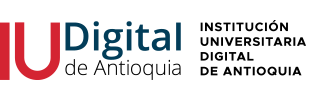
# Ingeniería de Software y Datos · IU Digital de Antioquia

Grupo:	40

Integrantes:	Jose Hilario Lopez / Dennyn Pandales

Facultad:	Ingeniería y Ciencias Agrícolas

Programa:	Ingeniería de Software y Datos

Asignatura:	Simulación - PREICA2602B020045

Catedràtico: Julian Andres Loaiza

Fecha de entrega	domingo 25 de Octubre

## 1. Mecánica del Juego y Distribución de Probabilidad
Se define el comportamiento de los dados estándar de 6 caras. Cada dado sigue una **distribución uniforme discreta**:

$$P(X = k) = \frac{1}{6}, \quad k \in \{1, 2, 3, 4, 5, 6\}$$

En esta sección se estructuran las funciones para el lanzamiento de los 5 dados y la evaluación analítica de las categorías del tablero de puntuación.

## 2. Estrategia de Selección y Algoritmo de Turno
Para modelar la toma de decisiones de los jugadores sin sesgos manuales, se aplica una **heurística de maximización de frecuencia**:
* El algoritmo identifica el valor numérico más repetido en la primera tirada y conserva dicho grupo.
* Se ejecutan hasta **3 lanzamientos por turno**.
* Al finalizar, se asigna dinámicamente el resultado a la categoría disponible que otorgue el mayor puntaje posible.

## 3. Motor de Simulación de Montecarlo
Se ejecutan **5,000 partidas completas** (13 turnos por jugador por partida, sumando 130,000 turnos simulados en total) para garantizar la convergencia de la ley de los grandes números sobre los puntajes medios y la varianza.

## 4. Visualización Gráfica e Interpretación Estocástica
Generación de histogramas de frecuencia con estimación de densidad de kernel (KDE) y diagramas de caja (*boxplots*) para evaluar la dispersión de los datos y comparar el rendimiento entre ambos jugadores.

Iniciando simulación Montecarlo (5000 partidas, 2 jugadores)...

=== MUESTRA DE DETALLE DE INTENTOS (PRIMERAS 15 PARTIDAS) ===
 Partida  Puntaje J1  Puntaje J2   Ganador Yahtzee J1 Yahtzee J2
       1         201         140 Jugador 1         Sí         No
       2         176         230 Jugador 2         No         Sí
       3         141         126 Jugador 1         No         No
       4         143         199 Jugador 2         No         Sí
       5         191         151 Jugador 1         Sí         No
       6         136         199 Jugador 2         Sí         No
       7         144         119 Jugador 1         Sí         No
       8         131         162 Jugador 2         No         Sí
       9          97         169 Jugador 2         No         No
      10         213         163 Jugador 1         No         No
      11          97         167 Jugador 2         No         Sí
      12         140         190 Jugador 2         No         No
      13         160        

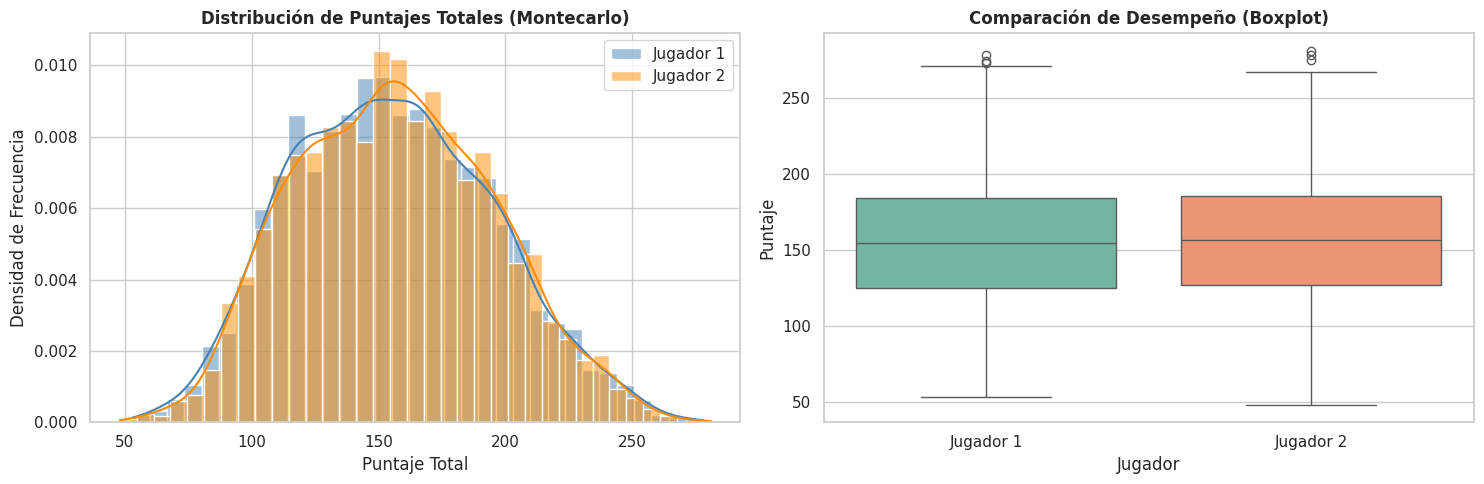

In [1]:
import random
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Configuración de estilo gráfico
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)

# ==========================================
# 1. FUNCIONES BASE DE DADOS Y EVALUACIÓN
# ==========================================


def lanzar_dados(n=5):
    """Simula el lanzamiento de n dados (Distribución Uniforme Discreta P(X=k)=1/6)."""
    return [random.randint(1, 6) for _ in range(n)]


def evaluar_categoria(dados, categoria):
    """Calcula el puntaje asignado a una categoría según la combinación de dados."""
    conteo = {i: dados.count(i) for i in set(dados)}
    valores = list(conteo.values())

    # Categorías superiores (1 a 6)
    if isinstance(categoria, int):
        return dados.count(categoria) * categoria

    # Categorías inferiores
    if categoria == "Tercia":
        return sum(dados) if any(v >= 3 for v in valores) else 0
    elif categoria == "Poker":
        return sum(dados) if any(v >= 4 for v in valores) else 0
    elif categoria == "Full House":
        return (
            25 if (3 in valores and 2 in valores) or 5 in valores else 0
        )
    elif categoria == "Escalera Menor":
        unicos = set(dados)
        subsets = [{1, 2, 3, 4}, {2, 3, 4, 5}, {3, 4, 5, 6}]
        return 30 if any(s.issubset(unicos) for s in subsets) else 0
    elif categoria == "Escalera Mayor":
        unicos = sorted(list(set(dados)))
        return 40 if unicos in [[1, 2, 3, 4, 5], [2, 3, 4, 5, 6]] else 0
    elif categoria == "Yahtzee":
        return 50 if 5 in valores else 0
    elif categoria == "Chance":
        return sum(dados)
    return 0


# ==========================================
# 2. ESTRATEGIA Y SIMULACIÓN DE TURNO
# ==========================================


def estrategia_seleccion_dados(dados):
    """Estrategia heurística: conserva el grupo numérico con mayor frecuencia."""
    conteo = {x: dados.count(x) for x in set(dados)}
    max_frec = max(conteo.values())
    dados_a_retener = [num for num, frec in conteo.items() if frec == max_frec]
    return [d for d in dados if d in dados_a_retener]


def simular_turno_jugador(categorias_disponibles):
    """Ejecuta hasta 3 tiros por turno y selecciona la mejor categoría disponible."""
    dados = lanzar_dados(5)

    for _ in range(2):
        retener = estrategia_seleccion_dados(dados)
        if len(retener) == 5:
            break
        nuevos_dados = lanzar_dados(5 - len(retener))
        dados = retener + nuevos_dados

    mejor_puntaje = -1
    mejor_cat = None

    for cat in categorias_disponibles:
        ptos = evaluar_categoria(dados, cat)
        if ptos > mejor_puntaje:
            mejor_puntaje = ptos
            mejor_cat = cat

    return mejor_cat, mejor_puntaje


def simular_partida_2_jugadores():
    """Simula una partida completa (13 turnos por jugador)."""
    categorias = [
        1,
        2,
        3,
        4,
        5,
        6,
        "Tercia",
        "Poker",
        "Full House",
        "Escalera Menor",
        "Escalera Mayor",
        "Yahtzee",
        "Chance",
    ]

    puntuaciones = {"Jugador 1": 0, "Jugador 2": 0}
    exitos_yahtzee = {"Jugador 1": 0, "Jugador 2": 0}

    for jugador in ["Jugador 1", "Jugador 2"]:
        cats_disponibles = categorias.copy()
        for _ in range(len(categorias)):
            cat, ptos = simular_turno_jugador(cats_disponibles)
            puntuaciones[jugador] += ptos
            cats_disponibles.remove(cat)
            if cat == "Yahtzee" and ptos == 50:
                exitos_yahtzee[jugador] = 1

    return (
        puntuaciones["Jugador 1"],
        puntuaciones["Jugador 2"],
        exitos_yahtzee["Jugador 1"],
        exitos_yahtzee["Jugador 2"],
    )


# ==========================================
# 3. EJECUCIÓN MONTECARLO (N = 5000 PARTIDAS)
# ==========================================

N_SIMULACIONES = 5000
print(
    f"Iniciando simulación Montecarlo ({N_SIMULACIONES} partidas, 2 jugadores)...\n"
)

res_j1, res_j2 = [], []
yahtzees_j1, yahtzees_j2 = 0, 0
historial_partidas = []

for i in range(1, N_SIMULACIONES + 1):
    p1, p2, y1, y2 = simular_partida_2_jugadores()
    res_j1.append(p1)
    res_j2.append(p2)
    yahtzees_j1 += y1
    yahtzees_j2 += y2

    historial_partidas.append(
        {
            "Partida": i,
            "Puntaje J1": p1,
            "Puntaje J2": p2,
            "Ganador": (
                "Jugador 1"
                if p1 > p2
                else ("Jugador 2" if p2 > p1 else "Empate")
            ),
            "Yahtzee J1": "Sí" if y1 == 1 else "No",
            "Yahtzee J2": "Sí" if y2 == 1 else "No",
        }
    )

df_historial = pd.DataFrame(historial_partidas)

# ==========================================
# 4. RESULTADOS Y ESTADÍSTICAS
# ==========================================

print("=== MUESTRA DE DETALLE DE INTENTOS (PRIMERAS 15 PARTIDAS) ===")
print(df_historial.head(15).to_string(index=False))
print("\n" + "=" * 70)

media_j1, std_j1 = np.mean(res_j1), np.std(res_j1)
media_j2, std_j2 = np.mean(res_j2), np.std(res_j2)
prob_yahtzee = ((yahtzees_j1 + yahtzees_j2) / (N_SIMULACIONES * 2)) * 100

print("\n--- RESUMEN ESTADÍSTICO MONTECARLO ---")
print(f"Jugador 1 - Promedio: {media_j1:.2f} pts | Desv. Estándar: {std_j1:.2f}")
print(f"Jugador 2 - Promedio: {media_j2:.2f} pts | Desv. Estándar: {std_j2:.2f}")
print(f"Frecuencia acumulada de Yahtzee por partida: {prob_yahtzee:.2f}%")

# ==========================================
# 5. VISUALIZACIÓN GRÁFICA
# ==========================================

fig, ax = plt.subplots(1, 2, figsize=(15, 5))

# Histograma con KDE
sns.histplot(
    res_j1,
    kde=True,
    color="steelblue",
    label="Jugador 1",
    ax=ax[0],
    stat="density",
)
sns.histplot(
    res_j2,
    kde=True,
    color="darkorange",
    label="Jugador 2",
    ax=ax[0],
    stat="density",
    alpha=0.5,
)
ax[0].set_title(
    "Distribución de Puntajes Totales (Montecarlo)", fontsize=12, fontweight="bold"
)
ax[0].set_xlabel("Puntaje Total")
ax[0].set_ylabel("Densidad de Frecuencia")
ax[0].legend()

# Diagrama de caja (Boxplot)
df_res = pd.DataFrame(
    {
        "Jugador": ["Jugador 1"] * N_SIMULACIONES
        + ["Jugador 2"] * N_SIMULACIONES,
        "Puntaje": res_j1 + res_j2,
    }
)
sns.boxplot(
    x="Jugador",
    y="Puntaje",
    hue="Jugador",
    data=df_res,
    ax=ax[1],
    palette="Set2",
    legend=False,
)
ax[1].set_title(
    "Comparación de Desempeño (Boxplot)", fontsize=12, fontweight="bold"
)

plt.tight_layout()
plt.show()